# Deep Learning Approaches for Aptamer–Molecule Prediction
This notebook evaluates **deep learning model** for aptamer–molecule prediction, combining sequence and molecular encoders with neural architectures, and compares them with classical baselines. 

In [18]:
# Add project root to sys.path
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "src").exists() and root.parent != root:
    root = root.parent

sys.path.insert(0, str(root))


In [19]:
import os
import json
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
from collections import defaultdict

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam, AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    matthews_corrcoef, mean_squared_error, mean_absolute_error, r2_score
)

# Optuna
import optuna
from optuna.samplers import TPESampler

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import seaborn as sns

# Model visualization and parameter counting
try:
    from torchinfo import summary
    TORCHINFO_AVAILABLE = True
except ImportError:
    TORCHINFO_AVAILABLE = False
    print("⚠ torchinfo not available - will use manual parameter counting")

# Set random seeds
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")


⚠ torchinfo not available - will use manual parameter counting
Using device: cuda


### 1.2. Reuse Existing Project Functions (with Fallbacks)


In [20]:
# Try to import existing functions, create fallbacks if needed

# === Data Loading ===
try:
    from src.models.screening import load_splits
    print("✓ Using existing load_splits")
except ImportError:
    def load_splits(split_mode, base_dir="../dataset/splits"):
        """Fallback: Load precomputed splits from JSON."""
        path = os.path.join(base_dir, f"{split_mode}.json")
        with open(path, "r") as f:
            data = json.load(f)
        return [(np.array(d["train_idx"]), np.array(d["val_idx"])) for d in data]
    print("⚠ Created fallback load_splits")

# === Encoders ===
try:
    from src.encoders.aptamer_encoders import (
        onehot_with_type_bit, kmer_freq_with_type_bit,
        gena_embed, dnabert2_embed
    )
    print("✓ Using existing aptamer encoders")
except ImportError:
    print("⚠ Aptamer encoders not found - will need to implement fallbacks")

try:
    from src.encoders.molecule_encoders import (
        morgan_fp, maccs_fp, physchem_descriptors,
        chemberta_embed, unimol_embed, molformer_embed
    )
    print("✓ Using existing molecule encoders")
except ImportError:
    print("⚠ Molecule encoders not found - will need to implement fallbacks")


✓ Using existing load_splits
✓ Using existing aptamer encoders
✓ Using existing molecule encoders


### 1.4. Model Visualization and Parameter Counting Utilities


In [21]:
def count_parameters(model):
    """Count total and trainable parameters in a model."""
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {
        'total': total_params,
        'trainable': trainable_params,
        'non_trainable': total_params - trainable_params
    }


def format_parameter_count(count):
    """Format parameter count in human-readable format."""
    if count >= 1e9:
        return f"{count / 1e9:.2f}B"
    elif count >= 1e6:
        return f"{count / 1e6:.2f}M"
    elif count >= 1e3:
        return f"{count / 1e3:.2f}K"
    else:
        return str(count)


def visualize_model_architecture(model, model_name, apt_dim, mol_dim, save_path=None):
    """
    Visualize model architecture as a diagram.
    """
    from matplotlib.patches import FancyArrowPatch
    
    fig, ax = plt.subplots(1, 1, figsize=(14, 10))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 12)
    ax.axis('off')
    
    # Title
    ax.text(5, 11.5, f"{model_name} Architecture", 
            ha='center', va='top', fontsize=16, fontweight='bold')
    
    # Count parameters
    params = count_parameters(model)
    param_text = f"Total: {format_parameter_count(params['total'])} | "
    param_text += f"Trainable: {format_parameter_count(params['trainable'])}"
    ax.text(5, 11, param_text, ha='center', va='top', fontsize=10, style='italic')
    
    # Draw architecture based on model type
    if 'PretrainedEncoder' in model_name:
        # Aptamer branch
        apt_box = FancyBboxPatch((0.5, 8), 2, 1.5, boxstyle="round,pad=0.1", 
                                facecolor='lightblue', edgecolor='black', linewidth=2)
        ax.add_patch(apt_box)
        ax.text(1.75, 9, f"Aptamer\nInput\n({apt_dim})", ha='center', va='center', fontsize=9)
        
        # Molecule branch
        mol_box = FancyBboxPatch((7.5, 8), 2, 1.5, boxstyle="round,pad=0.1",
                                facecolor='lightgreen', edgecolor='black', linewidth=2)
        ax.add_patch(mol_box)
        ax.text(8.75, 9, f"Molecule\nInput\n({mol_dim})", ha='center', va='center', fontsize=9)
        
        # Projection layers
        apt_proj = FancyBboxPatch((0.5, 6), 2, 1, boxstyle="round,pad=0.1",
                                 facecolor='lightblue', edgecolor='black', linewidth=1.5)
        ax.add_patch(apt_proj)
        ax.text(1.75, 6.5, "Projection\nLayers", ha='center', va='center', fontsize=8)
        
        mol_proj = FancyBboxPatch((7.5, 6), 2, 1, boxstyle="round,pad=0.1",
                                 facecolor='lightgreen', edgecolor='black', linewidth=1.5)
        ax.add_patch(mol_proj)
        ax.text(8.75, 6.5, "Projection\nLayers", ha='center', va='center', fontsize=8)
        
        # Fusion
        fusion_box = FancyBboxPatch((3.5, 4), 3, 1.5, boxstyle="round,pad=0.1",
                                   facecolor='lightyellow', edgecolor='black', linewidth=2)
        ax.add_patch(fusion_box)
        ax.text(5, 4.75, "Fusion Head\n(Concatenate + MLP)", ha='center', va='center', fontsize=9)
        
        # Output
        out_box = FancyBboxPatch((4.5, 2), 1, 0.8, boxstyle="round,pad=0.1",
                                facecolor='lightcoral', edgecolor='black', linewidth=2)
        ax.add_patch(out_box)
        ax.text(5, 2.4, "Output\n(Logits)", ha='center', va='center', fontsize=9)
        
        # Arrows
        arrow1 = FancyArrowPatch((1.75, 8), (1.75, 7.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow1)
        arrow2 = FancyArrowPatch((8.75, 8), (8.75, 7.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow2)
        arrow3 = FancyArrowPatch((1.75, 6), (3.5, 5.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow3)
        arrow4 = FancyArrowPatch((8.75, 6), (6.5, 5.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow4)
        arrow5 = FancyArrowPatch((5, 4), (5, 3.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow5)
        
    elif 'TwoTower' in model_name:
        # Two towers
        apt_tower = FancyBboxPatch((0.5, 7), 2.5, 3, boxstyle="round,pad=0.1",
                                   facecolor='lightblue', edgecolor='black', linewidth=2)
        ax.add_patch(apt_tower)
        ax.text(1.75, 8.5, "Aptamer Tower\n(MLP Layers)", ha='center', va='center', fontsize=9)
        
        mol_tower = FancyBboxPatch((7, 7), 2.5, 3, boxstyle="round,pad=0.1",
                                  facecolor='lightgreen', edgecolor='black', linewidth=2)
        ax.add_patch(mol_tower)
        ax.text(8.25, 8.5, "Molecule Tower\n(MLP Layers)", ha='center', va='center', fontsize=9)
        
        # Fusion
        fusion_box = FancyBboxPatch((3.5, 4), 3, 1.5, boxstyle="round,pad=0.1",
                                   facecolor='lightyellow', edgecolor='black', linewidth=2)
        ax.add_patch(fusion_box)
        ax.text(5, 4.75, "Fusion Layers\n(MLP)", ha='center', va='center', fontsize=9)
        
        # Output
        out_box = FancyBboxPatch((4.5, 2), 1, 0.8, boxstyle="round,pad=0.1",
                                facecolor='lightcoral', edgecolor='black', linewidth=2)
        ax.add_patch(out_box)
        ax.text(5, 2.4, "Output", ha='center', va='center', fontsize=9)
        
        # Arrows
        arrow1 = FancyArrowPatch((1.75, 7), (1.75, 6.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow1)
        arrow2 = FancyArrowPatch((8.25, 7), (8.25, 6.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow2)
        arrow3 = FancyArrowPatch((1.75, 6.5), (3.5, 5.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow3)
        arrow4 = FancyArrowPatch((8.25, 6.5), (6.5, 5.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow4)
        arrow5 = FancyArrowPatch((5, 4), (5, 3.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow5)
        
    elif 'CrossAttention' in model_name:
        # Inputs
        apt_in = FancyBboxPatch((0.5, 8.5), 2, 1, boxstyle="round,pad=0.1",
                               facecolor='lightblue', edgecolor='black', linewidth=2)
        ax.add_patch(apt_in)
        ax.text(1.75, 9, f"Aptamer\n({apt_dim})", ha='center', va='center', fontsize=9)
        
        mol_in = FancyBboxPatch((7.5, 8.5), 2, 1, boxstyle="round,pad=0.1",
                               facecolor='lightgreen', edgecolor='black', linewidth=2)
        ax.add_patch(mol_in)
        ax.text(8.75, 9, f"Molecule\n({mol_dim})", ha='center', va='center', fontsize=9)
        
        # Projections
        apt_proj = FancyBboxPatch((0.5, 7), 2, 0.8, boxstyle="round,pad=0.1",
                                 facecolor='lightblue', edgecolor='black', linewidth=1.5)
        ax.add_patch(apt_proj)
        ax.text(1.75, 7.4, "Project", ha='center', va='center', fontsize=8)
        
        mol_proj = FancyBboxPatch((7.5, 7), 2, 0.8, boxstyle="round,pad=0.1",
                                 facecolor='lightgreen', edgecolor='black', linewidth=1.5)
        ax.add_patch(mol_proj)
        ax.text(8.75, 7.4, "Project", ha='center', va='center', fontsize=8)
        
        # Cross-attention
        attn_box = FancyBboxPatch((3, 5), 4, 1.5, boxstyle="round,pad=0.1",
                                 facecolor='lightyellow', edgecolor='black', linewidth=2)
        ax.add_patch(attn_box)
        ax.text(5, 5.75, "Cross-Attention\nLayers", ha='center', va='center', fontsize=9)
        
        # Classifier
        cls_box = FancyBboxPatch((3.5, 3), 3, 1, boxstyle="round,pad=0.1",
                                facecolor='lightcoral', edgecolor='black', linewidth=2)
        ax.add_patch(cls_box)
        ax.text(5, 3.5, "Classifier Head", ha='center', va='center', fontsize=9)
        
        # Output
        out_box = FancyBboxPatch((4.5, 1.5), 1, 0.8, boxstyle="round,pad=0.1",
                                facecolor='lightcoral', edgecolor='black', linewidth=2)
        ax.add_patch(out_box)
        ax.text(5, 1.9, "Output", ha='center', va='center', fontsize=9)
        
        # Arrows
        arrow1 = FancyArrowPatch((1.75, 8.5), (1.75, 8.2), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow1)
        arrow2 = FancyArrowPatch((8.75, 8.5), (8.75, 8.2), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow2)
        arrow3 = FancyArrowPatch((1.75, 7), (3, 6.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow3)
        arrow4 = FancyArrowPatch((8.75, 7), (7, 6.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow4)
        arrow5 = FancyArrowPatch((5, 5), (5, 4.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow5)
        arrow6 = FancyArrowPatch((5, 3), (5, 2.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow6)
        
    elif 'MultiTask' in model_name:
        # Inputs
        input_box = FancyBboxPatch((3, 9), 4, 1, boxstyle="round,pad=0.1",
                                   facecolor='lightblue', edgecolor='black', linewidth=2)
        ax.add_patch(input_box)
        ax.text(5, 9.5, f"Concatenated Input\n({apt_dim + mol_dim})", ha='center', va='center', fontsize=9)
        
        # Shared encoder
        shared_box = FancyBboxPatch((2.5, 7), 5, 1.5, boxstyle="round,pad=0.1",
                                    facecolor='lightyellow', edgecolor='black', linewidth=2)
        ax.add_patch(shared_box)
        ax.text(5, 7.75, "Shared Encoder\n(MLP Layers)", ha='center', va='center', fontsize=9)
        
        # Task heads
        cls_head = FancyBboxPatch((1, 4.5), 2.5, 1.5, boxstyle="round,pad=0.1",
                                 facecolor='lightcoral', edgecolor='black', linewidth=2)
        ax.add_patch(cls_head)
        ax.text(2.25, 5.25, "Classification\nHead", ha='center', va='center', fontsize=9)
        
        reg_head = FancyBboxPatch((6.5, 4.5), 2.5, 1.5, boxstyle="round,pad=0.1",
                                 facecolor='lightgreen', edgecolor='black', linewidth=2)
        ax.add_patch(reg_head)
        ax.text(7.75, 5.25, "Regression\nHead", ha='center', va='center', fontsize=9)
        
        # Outputs
        cls_out = FancyBboxPatch((1.5, 2.5), 1.5, 0.8, boxstyle="round,pad=0.1",
                                facecolor='lightcoral', edgecolor='black', linewidth=2)
        ax.add_patch(cls_out)
        ax.text(2.25, 2.9, "Cls\nOutput", ha='center', va='center', fontsize=8)
        
        reg_out = FancyBboxPatch((7, 2.5), 1.5, 0.8, boxstyle="round,pad=0.1",
                                facecolor='lightgreen', edgecolor='black', linewidth=2)
        ax.add_patch(reg_out)
        ax.text(7.75, 2.9, "Reg\nOutput", ha='center', va='center', fontsize=8)
        
        # Arrows
        arrow1 = FancyArrowPatch((5, 9), (5, 8.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow1)
        arrow2 = FancyArrowPatch((5, 7), (2.25, 6.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow2)
        arrow3 = FancyArrowPatch((5, 7), (7.75, 6.5), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow3)
        arrow4 = FancyArrowPatch((2.25, 4.5), (2.25, 4), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow4)
        arrow5 = FancyArrowPatch((7.75, 4.5), (7.75, 4), arrowstyle='->', mutation_scale=20, linewidth=1.5, color='black')
        ax.add_patch(arrow5)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Architecture saved to: {save_path}")
    plt.show()
    
    return params


print("✓ Visualization utilities ready")


✓ Visualization utilities ready


### 1.3. Metrics Utilities (with Fallbacks)


In [22]:
def compute_classification_metrics(y_true, y_pred, y_scores=None):
    """
    Compute classification metrics: MCC, ROC-AUC, PR-AUC, F1.
    
    Args:
        y_true: Ground truth binary labels
        y_pred: Binary predictions
        y_scores: Continuous scores (probabilities) for ROC/PR-AUC
    
    Returns:
        dict with metrics
    """
    metrics = {}
    
    # MCC
    metrics['MCC'] = matthews_corrcoef(y_true, y_pred)
    
    # F1
    metrics['F1'] = f1_score(y_true, y_pred, zero_division=0)
    
    # ROC-AUC and PR-AUC (require continuous scores)
    if y_scores is not None and len(np.unique(y_true)) > 1:
        metrics['ROC-AUC'] = roc_auc_score(y_true, y_scores)
        metrics['PR-AUC'] = average_precision_score(y_true, y_scores)
    else:
        metrics['ROC-AUC'] = np.nan
        metrics['PR-AUC'] = np.nan
    
    return metrics


def compute_regression_metrics(y_true, y_pred):
    """
    Compute regression metrics: RMSE, MAE, R².
    
    Args:
        y_true: Ground truth values
        y_pred: Predictions
    
    Returns:
        dict with metrics
    """
    metrics = {}
    metrics['RMSE'] = np.sqrt(mean_squared_error(y_true, y_pred))
    metrics['MAE'] = mean_absolute_error(y_true, y_pred)
    metrics['R2'] = r2_score(y_true, y_pred)
    return metrics


def aggregate_metrics(metrics_list):
    """
    Aggregate metrics across folds: mean ± std.
    
    Args:
        metrics_list: List of metric dicts (one per fold)
    
    Returns:
        dict with aggregated metrics
    """
    if not metrics_list:
        return {}
    
    # Collect all metric names
    all_keys = set()
    for m in metrics_list:
        all_keys.update(m.keys())
    
    aggregated = {}
    for key in all_keys:
        values = [m.get(key, np.nan) for m in metrics_list]
        values = np.array(values)
        values = values[~np.isnan(values)]  # Remove NaN
        
        if len(values) > 0:
            aggregated[f"{key} mean"] = np.mean(values)
            aggregated[f"{key} std"] = np.std(values)
        else:
            aggregated[f"{key} mean"] = np.nan
            aggregated[f"{key} std"] = np.nan
    
    return aggregated


print("✓ Metrics utilities ready")


✓ Metrics utilities ready


## 2. Data Loading and Preparation


In [23]:
# Paths
DATASET_PATH = "../dataset/AptaBench_dataset_v2.csv"
SPLITS_DIR = "../dataset/splits"
ARTIFACTS_DIR = "../artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)
os.makedirs(os.path.join(ARTIFACTS_DIR, "optuna"), exist_ok=True)
os.makedirs(os.path.join(ARTIFACTS_DIR, "metrics"), exist_ok=True)

# Load dataset
df = pd.read_csv(DATASET_PATH)
print(f"Dataset loaded: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nLabel distribution:\n{df['label'].value_counts()}")
print(f"\npKd statistics:\n{df['pKd_value'].describe()}")

# Prepare data
df = df.reset_index(drop=True)
y_class = df['label'].astype(int).values
y_reg = df['pKd_value'].values  # For regression task

# Check for missing pKd values
has_pkd = ~np.isnan(y_reg)
print(f"\nSamples with pKd: {has_pkd.sum()} / {len(df)}")


Dataset loaded: (6413, 8)
Columns: ['type', 'sequence', 'canonical_smiles', 'pKd_value', 'label', 'buffer', 'origin', 'source']

Label distribution:
label
1    3347
0    3066
Name: count, dtype: int64

pKd statistics:
count    2223.000000
mean        5.825420
std         1.696713
min        -0.477121
25%         4.853872
50%         5.744727
75%         6.812744
max        15.211125
Name: pKd_value, dtype: float64

Samples with pKd: 2223 / 6413


## 3. PyTorch Dataset and DataLoader


In [24]:
class AptamerMoleculeDataset(Dataset):
    """PyTorch Dataset for aptamer-molecule pairs."""
    
    def __init__(self, apt_features, mol_features, labels_class, labels_reg=None):
        """
        Args:
            apt_features: np.ndarray, aptamer features [N, D_apt]
            mol_features: np.ndarray, molecule features [N, D_mol]
            labels_class: np.ndarray, binary classification labels [N]
            labels_reg: np.ndarray, regression targets [N] (optional)
        """
        self.apt_features = torch.FloatTensor(apt_features)
        self.mol_features = torch.FloatTensor(mol_features)
        self.labels_class = torch.LongTensor(labels_class)
        self.labels_reg = torch.FloatTensor(labels_reg) if labels_reg is not None else None
    
    def __len__(self):
        return len(self.labels_class)
    
    def __getitem__(self, idx):
        item = {
            'apt': self.apt_features[idx],
            'mol': self.mol_features[idx],
            'label_class': self.labels_class[idx]
        }
        if self.labels_reg is not None:
            item['label_reg'] = self.labels_reg[idx]
        return item


print("✓ Dataset class defined")


✓ Dataset class defined


## 4. Deep Learning Model Architectures

### 4.1. Scenario 1: Pretrained Encoders + Unfreezing Layers


In [25]:
class PretrainedEncoderModel(nn.Module):
    """
    Scenario 1: Pretrained encoders (HF transformers) with unfreezing capability.
    Uses frozen base encoders + trainable projection layers + fusion head.
    """
    
    def __init__(
        self,
        apt_dim,
        mol_dim,
        hidden_dims=[512, 256, 128, 64],
        dropout=0.3,
        unfreeze_apt_layers=0,
        unfreeze_mol_layers=0,
        apt_encoder=None,
        mol_encoder=None
    ):
        super().__init__()
        self.apt_dim = apt_dim
        self.mol_dim = mol_dim
        self.apt_encoder = apt_encoder  # Optional: HF model wrapper
        self.mol_encoder = mol_encoder  # Optional: HF model wrapper
        
        # Deep projection layers for aptamer
        apt_layers = []
        prev_dim = apt_dim
        for dim in hidden_dims:
            apt_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        self.apt_proj = nn.Sequential(*apt_layers)
        
        # Deep projection layers for molecule
        mol_layers = []
        prev_dim = mol_dim
        for dim in hidden_dims:
            mol_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        self.mol_proj = nn.Sequential(*mol_layers)
        
        # Deep fusion head
        fusion_dim = hidden_dims[-1] * 2
        fusion_dims = [fusion_dim] + hidden_dims[:-1] + [hidden_dims[-1] // 2]
        fusion_layers = []
        for i in range(len(fusion_dims) - 1):
            fusion_layers.extend([
                nn.Linear(fusion_dims[i], fusion_dims[i+1]),
                nn.BatchNorm1d(fusion_dims[i+1]),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
        fusion_layers.append(nn.Linear(fusion_dims[-1], 1))
        self.fusion_head = nn.Sequential(*fusion_layers)
    
    def unfreeze_last_n_layers(self, encoder, n_layers):
        """Unfreeze last n layers of a transformer encoder."""
        if encoder is None:
            return
        # For HF models, iterate through encoder layers
        if hasattr(encoder, 'encoder') and hasattr(encoder.encoder, 'layer'):
            layers = encoder.encoder.layer
            total_layers = len(layers)
            for i in range(max(0, total_layers - n_layers), total_layers):
                for param in layers[i].parameters():
                    param.requires_grad = True
    
    def forward(self, apt, mol):
        # Project features through deep networks
        apt_emb = self.apt_proj(apt)
        mol_emb = self.mol_proj(mol)
        
        # Concatenate
        fused = torch.cat([apt_emb, mol_emb], dim=1)
        
        # Classification head
        logits = self.fusion_head(fused)
        return logits.squeeze(-1)


print("✓ Scenario 1 model defined")


✓ Scenario 1 model defined


### 4.2. Scenario 2: Feature-based Two-Tower MLP


In [26]:
class TwoTowerMLP(nn.Module):
    """
    Scenario 2: Feature-based two-tower architecture.
    Each tower processes its modality, then fusion layer combines them.
    """
    
    def __init__(
        self,
        apt_dim,
        mol_dim,
        tower_hidden_dims=[1024, 512, 256, 128],
        fusion_hidden_dims=[512, 256, 128, 64],
        dropout=0.3
    ):
        super().__init__()
        
        # Aptamer tower
        apt_layers = []
        prev_dim = apt_dim
        for dim in tower_hidden_dims:
            apt_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        self.apt_tower = nn.Sequential(*apt_layers)
        
        # Molecule tower
        mol_layers = []
        prev_dim = mol_dim
        for dim in tower_hidden_dims:
            mol_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        self.mol_tower = nn.Sequential(*mol_layers)
        
        # Fusion layers
        fusion_dim = tower_hidden_dims[-1] * 2
        fusion_layers = []
        prev_dim = fusion_dim
        for dim in fusion_hidden_dims:
            fusion_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        fusion_layers.append(nn.Linear(prev_dim, 1))
        self.fusion = nn.Sequential(*fusion_layers)
    
    def forward(self, apt, mol):
        apt_emb = self.apt_tower(apt)
        mol_emb = self.mol_tower(mol)
        
        # Concatenate
        fused = torch.cat([apt_emb, mol_emb], dim=1)
        
        # Output
        logits = self.fusion(fused)
        return logits.squeeze(-1)


print("✓ Scenario 2 model defined")


✓ Scenario 2 model defined


### 4.3. Scenario 3: Cross-Attention Fusion


In [27]:
class CrossAttentionFusion(nn.Module):
    """
    Cross-attention module for fusing aptamer and molecule representations.
    """
    
    def __init__(self, dim, n_heads=8, dropout=0.1):
        super().__init__()
        self.dim = dim
        self.n_heads = n_heads
        self.head_dim = dim // n_heads
        
        assert dim % n_heads == 0, "dim must be divisible by n_heads"
        
        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)
        self.layer_norm = nn.LayerNorm(dim)
    
    def forward(self, query, key_value):
        """
        Args:
            query: [B, L_q, D] - e.g., aptamer features
            key_value: [B, L_kv, D] - e.g., molecule features
        """
        B, L_q, D = query.shape
        L_kv = key_value.shape[1]
        
        # Projections
        Q = self.q_proj(query).view(B, L_q, self.n_heads, self.head_dim).transpose(1, 2)  # [B, H, L_q, d]
        K = self.k_proj(key_value).view(B, L_kv, self.n_heads, self.head_dim).transpose(1, 2)  # [B, H, L_kv, d]
        V = self.v_proj(key_value).view(B, L_kv, self.n_heads, self.head_dim).transpose(1, 2)  # [B, H, L_kv, d]
        
        # Attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.head_dim)  # [B, H, L_q, L_kv]
        attn = F.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        
        # Apply attention to values
        out = torch.matmul(attn, V)  # [B, H, L_q, d]
        out = out.transpose(1, 2).contiguous().view(B, L_q, D)  # [B, L_q, D]
        out = self.out_proj(out)
        
        # Residual + layer norm
        out = self.layer_norm(query + out)
        return out


class CrossAttentionModel(nn.Module):
    """
    Scenario 3: Cross-attention fusion model.
    Uses cross-attention to let aptamer and molecule attend to each other.
    """
    
    def __init__(
        self,
        apt_dim,
        mol_dim,
        hidden_dim=512,
        n_attention_layers=4,
        n_heads=16,
        dropout=0.3,
        classifier_hidden_dims=[512, 256, 128]
    ):
        super().__init__()
        
        # Deep projection to common dimension
        apt_proj_layers = [
            nn.Linear(apt_dim, hidden_dim * 2),
            nn.BatchNorm1d(hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim)
        ]
        self.apt_proj = nn.Sequential(*apt_proj_layers)
        
        mol_proj_layers = [
            nn.Linear(mol_dim, hidden_dim * 2),
            nn.BatchNorm1d(hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim)
        ]
        self.mol_proj = nn.Sequential(*mol_proj_layers)
        
        # Multiple cross-attention layers
        self.attention_layers = nn.ModuleList([
            CrossAttentionFusion(hidden_dim, n_heads, dropout)
            for _ in range(n_attention_layers)
        ])
        
        # Deep classification head
        cls_layers = []
        prev_dim = hidden_dim * 2
        for dim in classifier_hidden_dims:
            cls_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        cls_layers.append(nn.Linear(prev_dim, 1))
        self.classifier = nn.Sequential(*cls_layers)
    
    def forward(self, apt, mol):
        # Project to common dimension
        apt_emb = self.apt_proj(apt).unsqueeze(1)  # [B, 1, D]
        mol_emb = self.mol_proj(mol).unsqueeze(1)  # [B, 1, D]
        
        # Cross-attention: aptamer attends to molecule
        apt_attended = apt_emb
        for attn_layer in self.attention_layers:
            apt_attended = attn_layer(apt_attended, mol_emb)
        
        # Cross-attention: molecule attends to aptamer
        mol_attended = mol_emb
        for attn_layer in self.attention_layers:
            mol_attended = attn_layer(mol_attended, apt_emb)
        
        # Concatenate and classify
        fused = torch.cat([apt_attended.squeeze(1), mol_attended.squeeze(1)], dim=1)
        logits = self.classifier(fused)
        return logits.squeeze(-1)


print("✓ Scenario 3 model defined")


✓ Scenario 3 model defined


### 4.4. Scenario 4: Multi-Task (Classification + Regression)


In [28]:
class MultiTaskModel(nn.Module):
    """
    Scenario 4: Multi-task model with classification and regression heads.
    Shared encoder + two separate heads.
    """
    
    def __init__(
        self,
        apt_dim,
        mol_dim,
        shared_hidden_dims=[1024, 512, 256, 128],
        task_hidden_dims=[256, 128, 64],
        dropout=0.3
    ):
        super().__init__()
        
        # Deep shared encoder
        shared_layers = []
        prev_dim = apt_dim + mol_dim
        for dim in shared_hidden_dims:
            shared_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        self.shared_encoder = nn.Sequential(*shared_layers)
        
        # Deep Classification head
        cls_layers = []
        prev_dim = shared_hidden_dims[-1]
        for dim in task_hidden_dims:
            cls_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        cls_layers.append(nn.Linear(prev_dim, 1))
        self.classifier = nn.Sequential(*cls_layers)
        
        # Deep Regression head
        reg_layers = []
        prev_dim = shared_hidden_dims[-1]
        for dim in task_hidden_dims:
            reg_layers.extend([
                nn.Linear(prev_dim, dim),
                nn.BatchNorm1d(dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = dim
        reg_layers.append(nn.Linear(prev_dim, 1))
        self.regressor = nn.Sequential(*reg_layers)
    
    def forward(self, apt, mol):
        # Concatenate inputs
        x = torch.cat([apt, mol], dim=1)
        
        # Shared encoding
        shared = self.shared_encoder(x)
        
        # Task-specific heads
        cls_logits = self.classifier(shared).squeeze(-1)
        reg_pred = self.regressor(shared).squeeze(-1)
        
        return cls_logits, reg_pred


print("✓ Scenario 4 model defined")


✓ Scenario 4 model defined


### 4.5. Model Visualization and Parameter Counting


Creating and visualizing model architectures...


Model: PretrainedEncoderModel
Total parameters: 2.08M
Trainable parameters: 2.08M
✓ Architecture saved to: ../artifacts\figs\pretrainedencodermodel_architecture.png


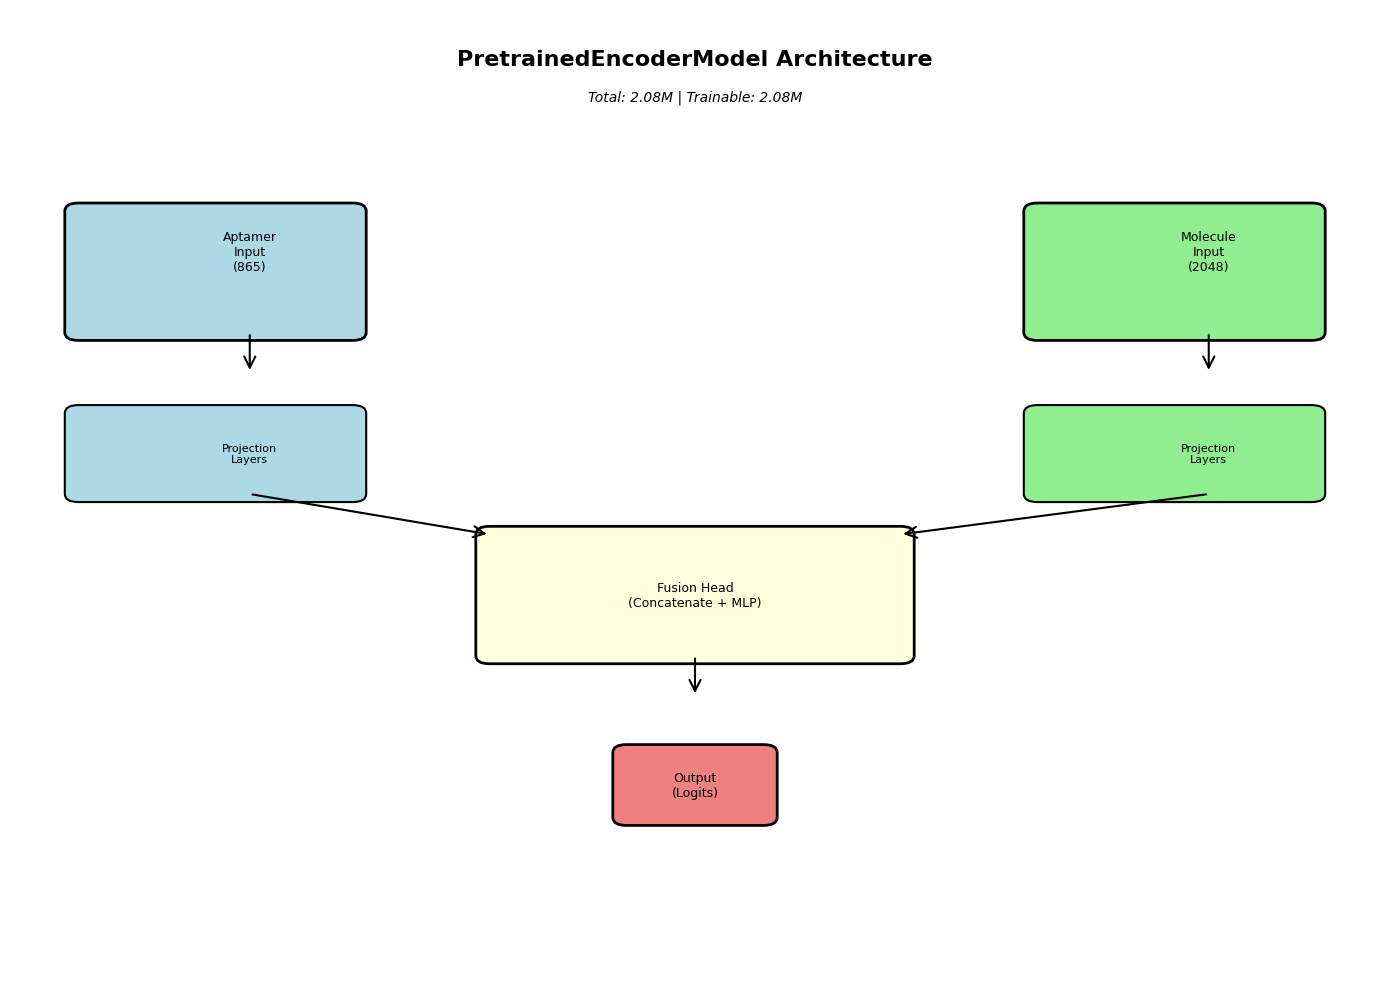


Model: TwoTowerMLP
Total parameters: 4.68M
Trainable parameters: 4.68M
✓ Architecture saved to: ../artifacts\figs\twotowermlp_architecture.png


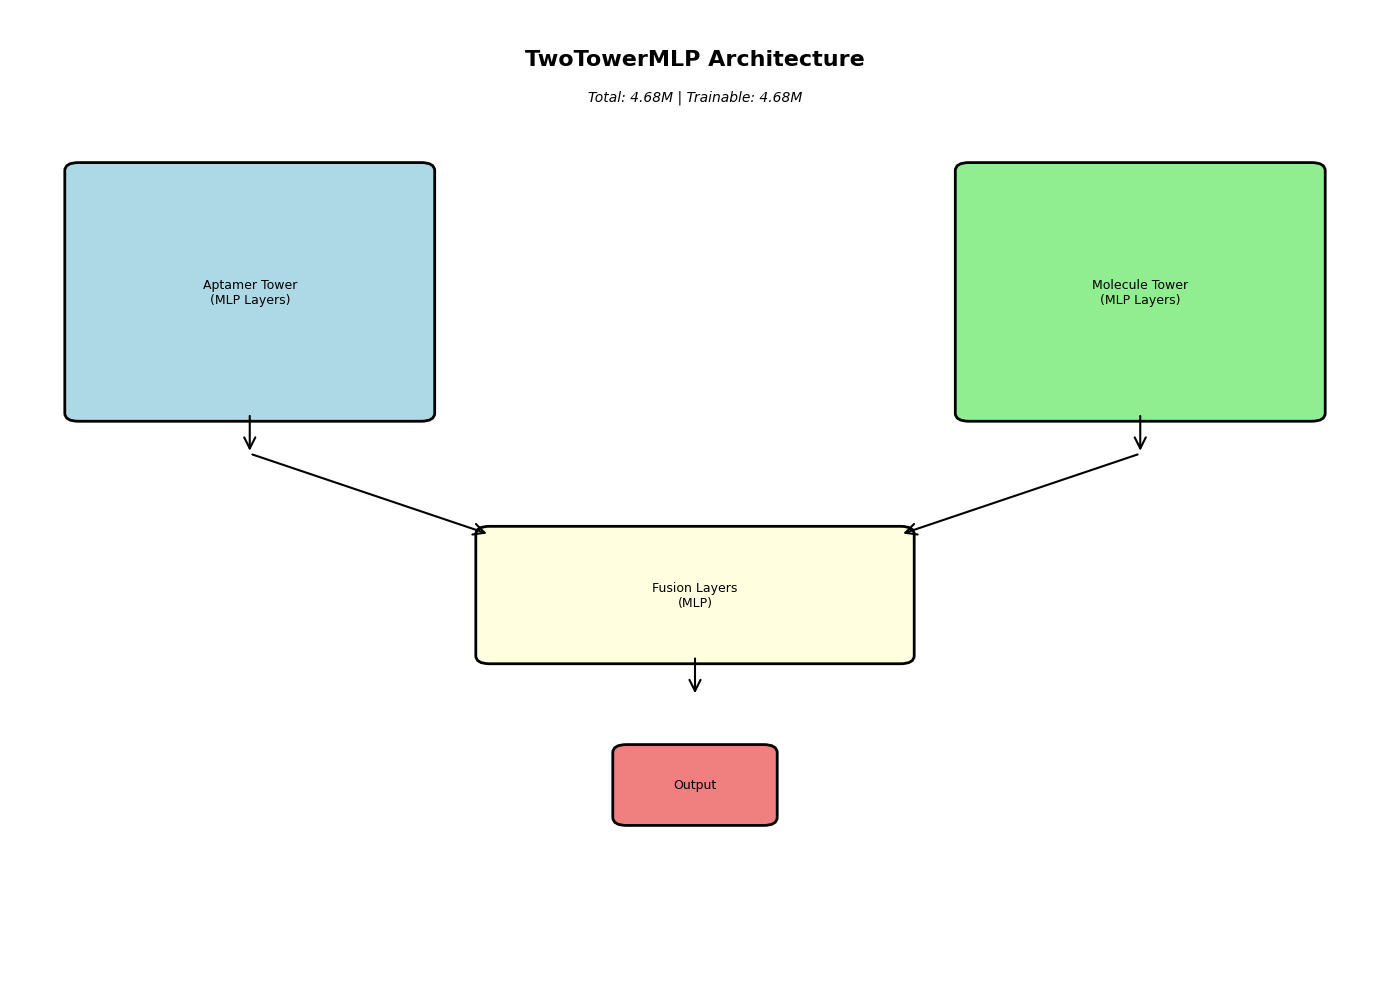


Model: CrossAttentionModel
Total parameters: 8.94M
Trainable parameters: 8.94M
✓ Architecture saved to: ../artifacts\figs\crossattentionmodel_architecture.png


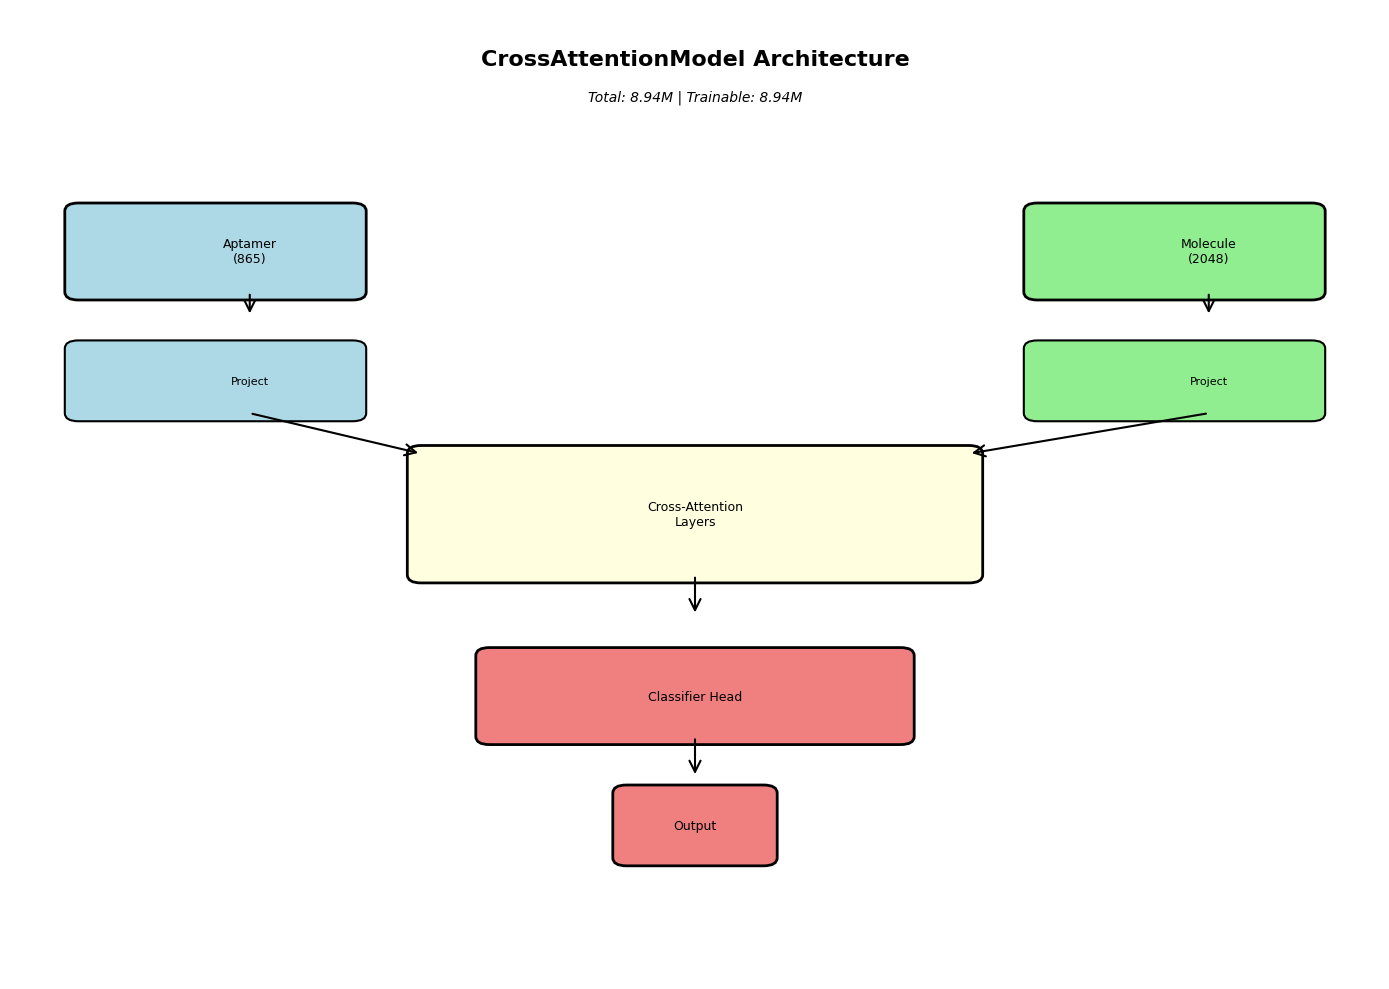


Model: MultiTaskModel
Total parameters: 3.83M
Trainable parameters: 3.83M
✓ Architecture saved to: ../artifacts\figs\multitaskmodel_architecture.png


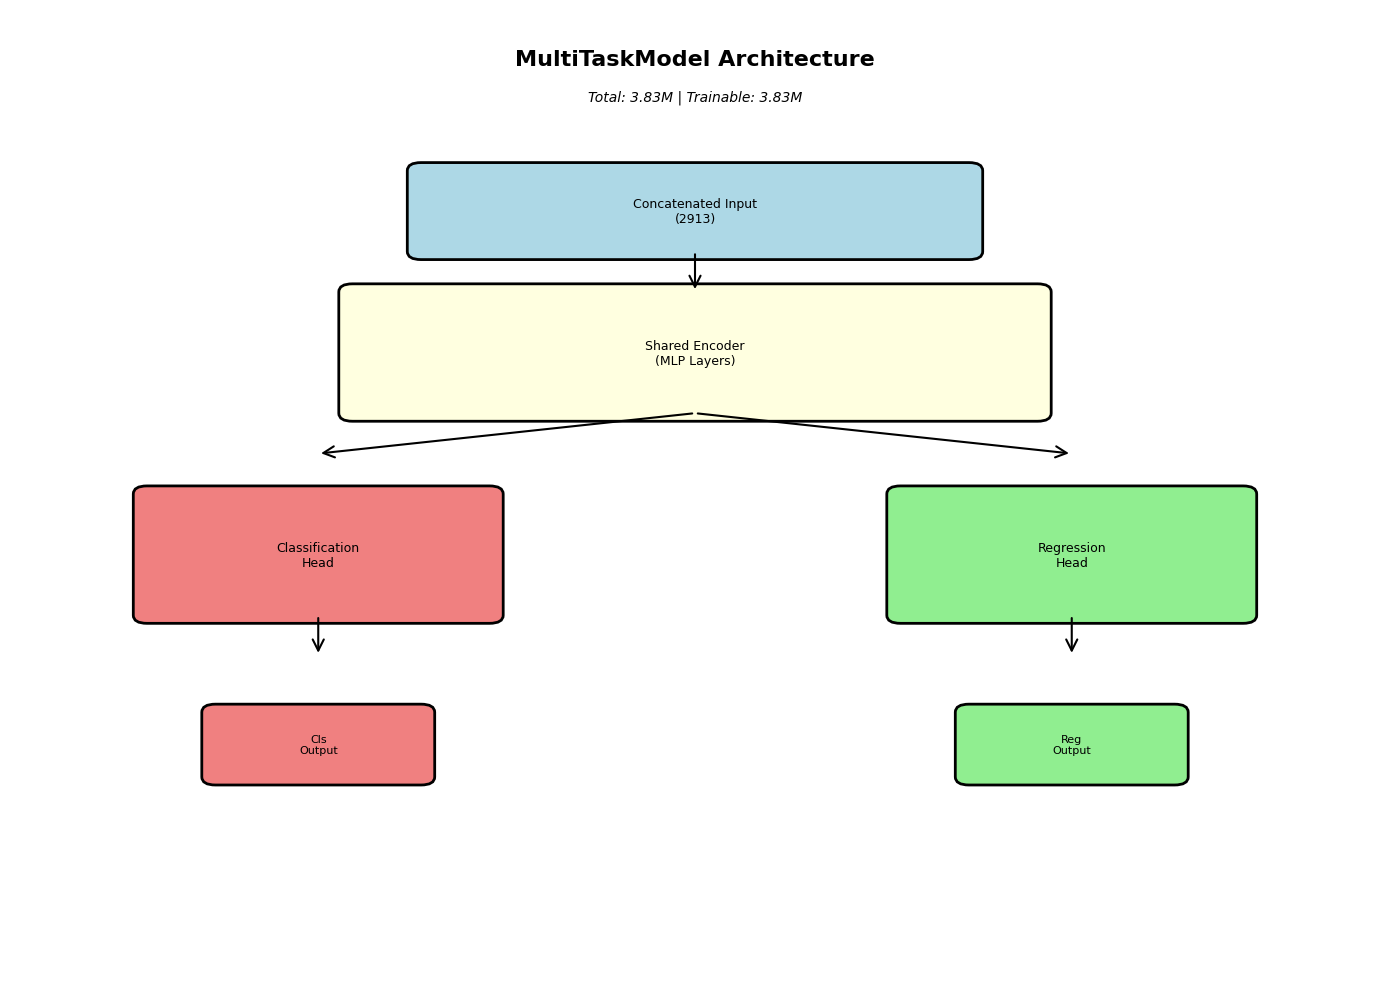


Model Parameters Summary
                 Model Total Parameters Trainable Parameters
   CrossAttentionModel            8.94M                8.94M
           TwoTowerMLP            4.68M                4.68M
        MultiTaskModel            3.83M                3.83M
PretrainedEncoderModel            2.08M                2.08M

✓ Parameters summary saved to: ../artifacts\metrics\model_parameters_summary.csv


In [29]:
# Create sample models for visualization
# We'll use example dimensions based on OneHot + MorganFP
sample_apt_dim = 865  # OneHot: 216*4 + 1 = 865
sample_mol_dim = 2048  # MorganFP: 2048

# Create models with sample dimensions
models_to_visualize = [
    (PretrainedEncoderModel, "PretrainedEncoderModel", sample_apt_dim, sample_mol_dim, 
     {"hidden_dims": [512, 256, 128, 64], "dropout": 0.3}),
    (TwoTowerMLP, "TwoTowerMLP", sample_apt_dim, sample_mol_dim,
     {"tower_hidden_dims": [1024, 512, 256, 128], "fusion_hidden_dims": [512, 256, 128, 64], "dropout": 0.3}),
    (CrossAttentionModel, "CrossAttentionModel", sample_apt_dim, sample_mol_dim,
     {"hidden_dim": 512, "n_attention_layers": 4, "n_heads": 16, "dropout": 0.3}),
    (MultiTaskModel, "MultiTaskModel", sample_apt_dim, sample_mol_dim,
     {"shared_hidden_dims": [1024, 512, 256, 128], "task_hidden_dims": [256, 128, 64], "dropout": 0.3}),
]

print("Creating and visualizing model architectures...\n")
os.makedirs(os.path.join(ARTIFACTS_DIR, "figs"), exist_ok=True)

model_params_summary = []

for model_class, model_name, apt_dim, mol_dim, kwargs in models_to_visualize:
    print(f"\n{'='*60}")
    print(f"Model: {model_name}")
    print(f"{'='*60}")
    
    # Create model
    model = model_class(apt_dim, mol_dim, **kwargs).to(device)
    
    # Count parameters
    params = count_parameters(model)
    model_params_summary.append({
        "Model": model_name,
        "Total Parameters": format_parameter_count(params['total']),
        "Trainable Parameters": format_parameter_count(params['trainable']),
        "Non-trainable Parameters": format_parameter_count(params['non_trainable']),
        "Total (raw)": params['total'],
        "Trainable (raw)": params['trainable']
    })
    
    print(f"Total parameters: {format_parameter_count(params['total'])}")
    print(f"Trainable parameters: {format_parameter_count(params['trainable'])}")
    
    # Visualize architecture
    save_path = os.path.join(ARTIFACTS_DIR, "figs", f"{model_name.lower()}_architecture.png")
    visualize_model_architecture(model, model_name, apt_dim, mol_dim, save_path=save_path)
    
    # Print model summary if torchinfo is available
    if TORCHINFO_AVAILABLE:
        print(f"\nDetailed model summary:")
        try:
            summary(model, input_size=[(1, apt_dim), (1, mol_dim)], device=device.type)
        except:
            print("  (Could not generate detailed summary)")

# Create summary table
params_df = pd.DataFrame(model_params_summary)
params_df = params_df.sort_values("Total (raw)", ascending=False)
print(f"\n{'='*60}")
print("Model Parameters Summary")
print(f"{'='*60}")
print(params_df[["Model", "Total Parameters", "Trainable Parameters"]].to_string(index=False))

# Save summary
params_summary_path = os.path.join(ARTIFACTS_DIR, "metrics", "model_parameters_summary.csv")
params_df.to_csv(params_summary_path, index=False)
print(f"\n✓ Parameters summary saved to: {params_summary_path}")


In [ ]:
!pip install git+https://github.com/ml-jku/clamp

### 6.1. Advanced Encoder Configurations (for Scenario 1)


In [ ]:
# Generate advanced features for Scenario 1 (pretrained encoders)
# These will be used for more sophisticated models

print("Generating advanced features for pretrained encoders...")

# Advanced aptamer encoders
advanced_apt_cfgs = [
    {"name": "GENA", "func": gena_embed, "kwargs": {"batch_size": 32}},
    {"name": "DNABERT2", "func": dnabert2_embed, "kwargs": {"batch_size": 16}},
]

# Advanced molecule encoders
advanced_mol_cfgs = [
    {"name": "ChemBERTa", "func": chemberta_embed, "kwargs": {"batch_size": 32}},
    {"name": "UniMol", "func": unimol_embed, "kwargs": {}},
    {"name": "MolFormer", "func": molformer_embed, "kwargs": {"batch_size": 16}},
]

# Precompute advanced features (optional - can be slow)
# Uncomment to use pretrained embeddings
advanced_apt_features_map = {}
advanced_mol_features_map = {}

for cfg in advanced_apt_cfgs:
    name = cfg["name"]
    print(f"  Computing {name}...")
    try:
        features = cfg["func"](df["sequence"].tolist(), **cfg.get("kwargs", {}))
        advanced_apt_features_map[name] = features
        print(f"    Shape: {features.shape}")
    except Exception as e:
        print(f"    Error: {e}")

for cfg in advanced_mol_cfgs:
    name = cfg["name"]
    print(f"  Computing {name}...")
    try:
        features = cfg["func"](df["canonical_smiles"].tolist(), **cfg.get("kwargs", {}))
        advanced_mol_features_map[name] = features
        print(f"    Shape: {features.shape}")
    except Exception as e:
        print(f"    Error: {e}")

print("\n✓ Advanced encoder configurations ready (commented out to save time)")
print("  Uncomment the code above to use pretrained embeddings (GENA, DNABERT2, ChemBERTa, etc.)")


Generating advanced features for pretrained encoders...
  Computing GENA...


The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


    Shape: (6413, 769)
  Computing DNABERT2...


Some weights of BertModel were not initialized from the model checkpoint at zhihan1996/DNABERT-2-117M and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


    Shape: (6413, 769)
  Computing ChemBERTa...
    Shape: (6413, 768)
  Computing UniMol...


2025-11-27 19:52:31 | unimol_tools\models\unimol.py | 167 | INFO | Uni-Mol Tools | Loading pretrained weights from c:\Users\m19er\AptaBench\.venv\lib\site-packages\unimol_tools\weights\mol_pre_all_h_220816.pt


## 5. Training Utilities


## 8. Optuna Hyperparameter Optimization


In [ ]:
def train_epoch(model, dataloader, optimizer, criterion, device, multitask=False, alpha=1.0, beta=1.0):
    """Train for one epoch."""
    model.train()
    total_loss = 0.0
    n_batches = 0
    
    for batch in dataloader:
        apt = batch['apt'].to(device)
        mol = batch['mol'].to(device)
        label_class = batch['label_class'].to(device)
        
        optimizer.zero_grad()
        
        if multitask:
            cls_logits, reg_pred = model(apt, mol)
            label_reg = batch['label_reg'].to(device)
            
            # Combined loss
            cls_loss = criterion['cls'](cls_logits, label_class.float())
            reg_loss = criterion['reg'](reg_pred, label_reg)
            loss = alpha * cls_loss + beta * reg_loss
        else:
            logits = model(apt, mol)
            loss = criterion(logits, label_class.float())
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        n_batches += 1
    
    return total_loss / max(n_batches, 1)


def train_with_history(model, train_loader, val_loader, optimizer, criterion, device, 
                       n_epochs=50, patience=10, multitask=False, alpha=1.0, beta=1.0):
    """
    Train model with full history tracking for visualization.
    
    Returns:
        history: dict with 'train_loss', 'val_loss', 'val_mcc', 'val_roc_auc', etc.
    """
    history = {
        'train_loss': [],
        'val_loss': [],
        'val_mcc': [],
        'val_roc_auc': [],
        'val_f1': []
    }
    
    best_val_score = -np.inf
    patience_counter = 0
    
    for epoch in range(n_epochs):
        # Training
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device, 
                                multitask=multitask, alpha=alpha, beta=beta)
        
        # Validation
        model.eval()
        val_loss = 0.0
        n_val_batches = 0
        all_preds_class = []
        all_scores = []
        all_labels_class = []
        
        with torch.no_grad():
            for batch in val_loader:
                apt = batch['apt'].to(device)
                mol = batch['mol'].to(device)
                label_class = batch['label_class'].to(device)
                
                if multitask:
                    cls_logits, reg_pred = model(apt, mol)
                    label_reg = batch['label_reg'].to(device)
                    cls_loss = criterion['cls'](cls_logits, label_class.float())
                    reg_loss = criterion['reg'](reg_pred, label_reg)
                    loss = alpha * cls_loss + beta * reg_loss
                    scores = torch.sigmoid(cls_logits).cpu().numpy()
                else:
                    logits = model(apt, mol)
                    loss = criterion(logits, label_class.float())
                    scores = torch.sigmoid(logits).cpu().numpy()
                
                val_loss += loss.item()
                n_val_batches += 1
                
                preds_class = (scores > 0.5).astype(int)
                all_preds_class.extend(preds_class)
                all_scores.extend(scores)
                all_labels_class.extend(label_class.cpu().numpy())
        
        val_loss = val_loss / max(n_val_batches, 1)
        val_metrics = compute_classification_metrics(
            np.array(all_labels_class),
            np.array(all_preds_class),
            np.array(all_scores)
        )
        
        # Update history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_mcc'].append(val_metrics.get('MCC', np.nan))
        history['val_roc_auc'].append(val_metrics.get('ROC-AUC', np.nan))
        history['val_f1'].append(val_metrics.get('F1', np.nan))
        
        # Early stopping
        val_score = val_metrics.get('MCC', -np.inf)
        if val_score > best_val_score:
            best_val_score = val_score
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
    
    return history


def evaluate(model, dataloader, device, multitask=False):
    """Evaluate model and return predictions and metrics."""
    model.eval()
    all_preds_class = []
    all_scores = []
    all_preds_reg = []
    all_labels_class = []
    all_labels_reg = []
    
    with torch.no_grad():
        for batch in dataloader:
            apt = batch['apt'].to(device)
            mol = batch['mol'].to(device)
            label_class = batch['label_class'].cpu().numpy()
            
            if multitask:
                cls_logits, reg_pred = model(apt, mol)
                scores = torch.sigmoid(cls_logits).cpu().numpy()
                preds_class = (scores > 0.5).astype(int)
                preds_reg = reg_pred.cpu().numpy()
                
                all_preds_reg.extend(preds_reg)
                if 'label_reg' in batch:
                    all_labels_reg.extend(batch['label_reg'].cpu().numpy())
            else:
                logits = model(apt, mol)
                scores = torch.sigmoid(logits).cpu().numpy()
                preds_class = (scores > 0.5).astype(int)
            
            all_preds_class.extend(preds_class)
            all_scores.extend(scores)
            all_labels_class.extend(label_class)
    
    results = {
        'y_true': np.array(all_labels_class),
        'y_pred': np.array(all_preds_class),
        'y_scores': np.array(all_scores)
    }
    
    if multitask and len(all_preds_reg) > 0:
        results['y_pred_reg'] = np.array(all_preds_reg)
        if len(all_labels_reg) > 0:
            results['y_true_reg'] = np.array(all_labels_reg)
    
    return results


print("✓ Training utilities defined")


✓ Training utilities defined


## 6. Baseline Model Configurations


In [ ]:
# Generate features using ALL available encoders
print("Generating features for ALL encoders...")

# Aptamer encoders - ALL available
apt_cfgs = [
    {"name": "OneHot", "func": onehot_with_type_bit},
    {"name": "Kmer3", "func": kmer_freq_with_type_bit, "kwargs": {"k": 3}},
    {"name": "Kmer4", "func": kmer_freq_with_type_bit, "kwargs": {"k": 4}},
    {"name": "GENA", "func": gena_embed, "kwargs": {"batch_size": 32}},
    {"name": "DNABERT2", "func": dnabert2_embed, "kwargs": {"batch_size": 16}},
]

# Molecule encoders - ALL available
mol_cfgs = [
    {"name": "MorganFP", "func": morgan_fp},
    {"name": "MACCS", "func": maccs_fp},
    {"name": "PhysChem", "func": physchem_descriptors},
    {"name": "ChemBERTa", "func": chemberta_embed, "kwargs": {"batch_size": 32}},
    {"name": "UniMol", "func": unimol_embed, "kwargs": {}},
    {"name": "MolFormer", "func": molformer_embed, "kwargs": {"batch_size": 16}},
]

# Precompute features
apt_features_map = {}
mol_features_map = {}

print("\n=== Aptamer Encoders ===")
for cfg in apt_cfgs:
    name = cfg["name"]
    print(f"  Computing {name}...", end=" ")
    try:
        features = cfg["func"](df["sequence"].tolist(), **cfg.get("kwargs", {}))
        apt_features_map[name] = features
        print(f"✓ Shape: {features.shape}")
    except Exception as e:
        print(f"✗ Error: {e}")

print("\n=== Molecule Encoders ===")
for cfg in mol_cfgs:
    name = cfg["name"]
    print(f"  Computing {name}...", end=" ")
    try:
        features = cfg["func"](df["canonical_smiles"].tolist(), **cfg.get("kwargs", {}))
        mol_features_map[name] = features
        print(f"✓ Shape: {features.shape}")
    except Exception as e:
        print(f"✗ Error: {e}")

print(f"\n✓ Features generated: {len(apt_features_map)} aptamer encoders, {len(mol_features_map)} molecule encoders")


Generating features...
  Computing OneHot...
    Shape: (6413, 865)
  Computing Kmer4...
    Shape: (6413, 257)
  Computing MorganFP...
    Shape: (6413, 2048)
  Computing PhysChem...
    Shape: (6413, 205)

✓ Features generated


## 7. Baseline Model Evaluation


In [16]:
def run_baseline_evaluation(
    model_class,
    apt_features,
    mol_features,
    y_class,
    y_reg,
    splits,
    model_kwargs=None,
    n_epochs=50,
    batch_size=64,
    lr=1e-3,
    multitask=False,
    alpha=1.0,
    beta=1.0
):
    """
    Run baseline evaluation for a model configuration.
    
    Returns:
        List of metric dicts (one per fold)
    """
    if model_kwargs is None:
        model_kwargs = {}
    
    apt_dim = apt_features.shape[1]
    mol_dim = mol_features.shape[1]
    
    all_fold_metrics = []
    
    for fold_idx, (train_idx, val_idx) in enumerate(splits):
        print(f"  Fold {fold_idx + 1}/{len(splits)}...", end=" ")
        
        # Split data
        apt_train, apt_val = apt_features[train_idx], apt_features[val_idx]
        mol_train, mol_val = mol_features[train_idx], mol_features[val_idx]
        y_class_train, y_class_val = y_class[train_idx], y_class[val_idx]
        y_reg_train = y_reg[train_idx] if y_reg is not None else None
        y_reg_val = y_reg[val_idx] if y_reg is not None else None
        
                # For multitask models, filter out NaN values in y_reg
        if multitask and y_reg_train is not None:
            # Filter train set
            valid_train_mask = ~np.isnan(y_reg_train)
            apt_train = apt_train[valid_train_mask]
            mol_train = mol_train[valid_train_mask]
            y_class_train = y_class_train[valid_train_mask]
            y_reg_train = y_reg_train[valid_train_mask]
            
            # Filter val set
            valid_val_mask = ~np.isnan(y_reg_val)
            apt_val = apt_val[valid_val_mask]
            mol_val = mol_val[valid_val_mask]
            y_class_val = y_class_val[valid_val_mask]
            y_reg_val = y_reg_val[valid_val_mask]
        
        # Normalize features
        scaler_apt = StandardScaler()
        scaler_mol = StandardScaler()
        apt_train = scaler_apt.fit_transform(apt_train)
        apt_val = scaler_apt.transform(apt_val)
        mol_train = scaler_mol.fit_transform(mol_train)
        mol_val = scaler_mol.transform(mol_val)
        
        # Create datasets
        train_dataset = AptamerMoleculeDataset(
            apt_train, mol_train, y_class_train, y_reg_train
        )
        val_dataset = AptamerMoleculeDataset(
            apt_val, mol_val, y_class_val, y_reg_val
        )
        
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        
        # Create model
        model = model_class(apt_dim, mol_dim, **model_kwargs).to(device)
        
        # Optimizer and loss
        optimizer = Adam(model.parameters(), lr=lr)
        if multitask:
            criterion = {
                'cls': nn.BCEWithLogitsLoss(),
                'reg': nn.MSELoss()
            }
        else:
            criterion = nn.BCEWithLogitsLoss()
        
        # Training loop
        best_val_score = -np.inf
        patience = 10
        patience_counter = 0
        
        for epoch in range(n_epochs):
            train_loss = train_epoch(
                model, train_loader, optimizer, criterion, device,
                multitask=multitask, alpha=alpha, beta=beta
            )
            
            # Validation
            val_results = evaluate(model, val_loader, device, multitask=multitask)
            val_metrics = compute_classification_metrics(
                val_results['y_true'],
                val_results['y_pred'],
                val_results['y_scores']
            )
            
            # Use MCC as validation score
            val_score = val_metrics['MCC']
            
            if val_score > best_val_score:
                best_val_score = val_score
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    break
        
        # Final evaluation
        val_results = evaluate(model, val_loader, device, multitask=multitask)
        fold_metrics = compute_classification_metrics(
            val_results['y_true'],
            val_results['y_pred'],
            val_results['y_scores']
        )
        
        # Add regression metrics if multitask
        if multitask and 'y_pred_reg' in val_results and 'y_true_reg' in val_results:
            reg_metrics = compute_regression_metrics(
                val_results['y_true_reg'],
                val_results['y_pred_reg']
            )
            fold_metrics.update(reg_metrics)
        
        all_fold_metrics.append(fold_metrics)
        print(f"MCC: {fold_metrics['MCC']:.3f}, ROC-AUC: {fold_metrics['ROC-AUC']:.3f}")
    
    return all_fold_metrics


print("✓ Baseline evaluation function defined")


✓ Baseline evaluation function defined


In [ ]:
# Updated run_baseline_evaluation with history tracking support
# This overrides the previous definition to add track_history parameter

def run_baseline_evaluation_with_history(
    model_class,
    apt_features,
    mol_features,
    y_class,
    y_reg,
    splits,
    model_kwargs=None,
    n_epochs=50,
    batch_size=64,
    lr=1e-3,
    multitask=False,
    alpha=1.0,
    beta=1.0,
    track_history=True
):
    """
    Run baseline evaluation for a model configuration with training history tracking.
    
    Returns:
        all_fold_metrics: List of metric dicts (one per fold)
        all_fold_histories: List of training histories (one per fold) if track_history=True
    """
    if model_kwargs is None:
        model_kwargs = {}
    
    apt_dim = apt_features.shape[1]
    mol_dim = mol_features.shape[1]
    
    all_fold_metrics = []
    all_fold_histories = []
    
    for fold_idx, (train_idx, val_idx) in enumerate(splits):
        print(f"  Fold {fold_idx + 1}/{len(splits)}...", end=" ")
        
        # Split data
        apt_train, apt_val = apt_features[train_idx], apt_features[val_idx]
        mol_train, mol_val = mol_features[train_idx], mol_features[val_idx]
        y_class_train, y_class_val = y_class[train_idx], y_class[val_idx]
        y_reg_train = y_reg[train_idx] if y_reg is not None else None
        y_reg_val = y_reg[val_idx] if y_reg is not None else None
        
        # For multitask models, filter out NaN values in y_reg
        if multitask and y_reg_train is not None:
            # Filter train set
            valid_train_mask = ~np.isnan(y_reg_train)
            apt_train = apt_train[valid_train_mask]
            mol_train = mol_train[valid_train_mask]
            y_class_train = y_class_train[valid_train_mask]
            y_reg_train = y_reg_train[valid_train_mask]
            
            # Filter val set
            valid_val_mask = ~np.isnan(y_reg_val)
            apt_val = apt_val[valid_val_mask]
            mol_val = mol_val[valid_val_mask]
            y_class_val = y_class_val[valid_val_mask]
            y_reg_val = y_reg_val[valid_val_mask]
        
        # Normalize features
        scaler_apt = StandardScaler()
        scaler_mol = StandardScaler()
        apt_train = scaler_apt.fit_transform(apt_train)
        apt_val = scaler_apt.transform(apt_val)
        mol_train = scaler_mol.fit_transform(mol_train)
        mol_val = scaler_mol.transform(mol_val)
        
        # Create datasets
        train_dataset = AptamerMoleculeDataset(
            apt_train, mol_train, y_class_train, y_reg_train
        )
        val_dataset = AptamerMoleculeDataset(
            apt_val, mol_val, y_class_val, y_reg_val
        )
        
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        
        # Create model
        model = model_class(apt_dim, mol_dim, **model_kwargs).to(device)
        
        # Optimizer and loss
        optimizer = Adam(model.parameters(), lr=lr)
        if multitask:
            criterion = {
                'cls': nn.BCEWithLogitsLoss(),
                'reg': nn.MSELoss()
            }
        else:
            criterion = nn.BCEWithLogitsLoss()
        
        # Training with history tracking
        if track_history:
            history = train_with_history(
                model, train_loader, val_loader, optimizer, criterion, device,
                n_epochs=n_epochs, patience=10, multitask=multitask, alpha=alpha, beta=beta
            )
            all_fold_histories.append(history)
        else:
            # Training loop without history
            best_val_score = -np.inf
            patience = 10
            patience_counter = 0
            
            for epoch in range(n_epochs):
                train_loss = train_epoch(
                    model, train_loader, optimizer, criterion, device,
                    multitask=multitask, alpha=alpha, beta=beta
                )
                
                # Validation
                val_results = evaluate(model, val_loader, device, multitask=multitask)
                val_metrics = compute_classification_metrics(
                    val_results['y_true'],
                    val_results['y_pred'],
                    val_results['y_scores']
                )
                
                # Use MCC as validation score
                val_score = val_metrics['MCC']
                
                if val_score > best_val_score:
                    best_val_score = val_score
                    patience_counter = 0
                else:
                    patience_counter += 1
                    if patience_counter >= patience:
                        break
        
        # Final evaluation
        val_results = evaluate(model, val_loader, device, multitask=multitask)
        fold_metrics = compute_classification_metrics(
            val_results['y_true'],
            val_results['y_pred'],
            val_results['y_scores']
        )
        
        # Add regression metrics if multitask
        if multitask and 'y_pred_reg' in val_results and 'y_true_reg' in val_results:
            reg_metrics = compute_regression_metrics(
                val_results['y_true_reg'],
                val_results['y_pred_reg']
            )
            fold_metrics.update(reg_metrics)
        
        all_fold_metrics.append(fold_metrics)
        print(f"MCC: {fold_metrics['MCC']:.3f}")
    
    if track_history:
        return all_fold_metrics, all_fold_histories
    else:
        return all_fold_metrics

# Override the original function
run_baseline_evaluation = run_baseline_evaluation_with_history

print("✓ Updated run_baseline_evaluation with history tracking support")


### 7.1. Run Baseline Models


In [ ]:
# Load splits
split_mode = "stratified"
splits = load_splits(split_mode, base_dir=SPLITS_DIR)
print(f"Loaded {len(splits)} folds for {split_mode} split")

# ============================================================
# COMPREHENSIVE ENCODER COMPARISON WITH TRAINING CURVES
# ============================================================

# Use TwoTowerMLP as the model (good balance of performance and speed)
model_class = TwoTowerMLP
model_kwargs = {
    "tower_hidden_dims": [1024, 512, 256, 128],
    "fusion_hidden_dims": [512, 256, 128, 64],
    "dropout": 0.3
}

# Store all results with training histories
comparison_results = []
all_histories = {}  # Store histories for visualization

print("\n" + "="*80)
print("COMPREHENSIVE ENCODER COMPARISON")
print("="*80)
print(f"Model: {model_class.__name__}")
print(f"Testing {len(apt_features_map)} aptamer encoders × {len(mol_features_map)} molecule encoders")
print("="*80 + "\n")

# Iterate through all encoder combinations
for apt_name, apt_feat in apt_features_map.items():
    for mol_name, mol_feat in mol_features_map.items():
        config_name = f"{apt_name} + {mol_name}"
        print(f"\n{'='*80}")
        print(f"Configuration: {config_name}")
        print(f"{'='*80}")
        
        try:
            # Run evaluation with history tracking
            metrics, histories = run_baseline_evaluation(
                model_class,
                apt_feat, mol_feat, y_class, y_reg,
                splits,
                model_kwargs=model_kwargs,
                n_epochs=30,
                lr=1e-3,
                track_history=True
            )
            
            # Aggregate metrics
            agg_metrics = aggregate_metrics(metrics)
            
            # Store results
            result = {
                "apt_encoder": apt_name,
                "mol_encoder": mol_name,
                "config": config_name,
                **agg_metrics
            }
            comparison_results.append(result)
            
            # Store histories for visualization
            all_histories[config_name] = histories
            
            print(f"\n✓ Completed: {config_name}")
            print(f"  MCC: {agg_metrics.get('MCC mean', np.nan):.3f} ± {agg_metrics.get('MCC std', np.nan):.3f}")
            print(f"  ROC-AUC: {agg_metrics.get('ROC-AUC mean', np.nan):.3f} ± {agg_metrics.get('ROC-AUC std', np.nan):.3f}")
            
        except Exception as e:
            print(f"\n✗ Error for {config_name}: {e}")
            continue

# Create results DataFrame
comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("MCC mean", ascending=False)

print("\n" + "="*80)
print("ENCODER COMPARISON RESULTS")
print("="*80)
print(comparison_df[["apt_encoder", "mol_encoder", "MCC mean", "MCC std", 
                     "ROC-AUC mean", "ROC-AUC std", "F1 mean"]].to_string(index=False))

# Save results
comparison_path = os.path.join(ARTIFACTS_DIR, "metrics", "encoder_comparison.csv")
comparison_df.to_csv(comparison_path, index=False)
print(f"\n✓ Results saved to: {comparison_path}")


Loaded 5 folds for stratified split

=== Scenario 1: PretrainedEncoderModel ===
  Fold 1/5... MCC: 0.687, ROC-AUC: 0.913
  Fold 2/5... MCC: 0.682, ROC-AUC: 0.913
  Fold 3/5... MCC: 0.665, ROC-AUC: 0.915
  Fold 4/5... MCC: 0.620, ROC-AUC: 0.898
  Fold 5/5... MCC: 0.634, ROC-AUC: 0.899

=== Scenario 2: TwoTowerMLP ===
  Fold 1/5... MCC: 0.703, ROC-AUC: 0.923
  Fold 2/5... MCC: 0.674, ROC-AUC: 0.907
  Fold 3/5... MCC: 0.680, ROC-AUC: 0.917
  Fold 4/5... MCC: 0.627, ROC-AUC: 0.899
  Fold 5/5... MCC: 0.622, ROC-AUC: 0.900

=== Scenario 3: CrossAttentionModel ===
  Fold 1/5... MCC: 0.698, ROC-AUC: 0.921
  Fold 2/5... MCC: 0.691, ROC-AUC: 0.922
  Fold 3/5... MCC: 0.691, ROC-AUC: 0.927
  Fold 4/5... MCC: 0.652, ROC-AUC: 0.909
  Fold 5/5... MCC: 0.673, ROC-AUC: 0.914

=== Scenario 4: MultiTaskModel ===
  Fold 1/5... MCC: 0.585, ROC-AUC: 0.902
  Fold 2/5... MCC: 0.568, ROC-AUC: 0.854
  Fold 3/5... MCC: 0.596, ROC-AUC: 0.860
  Fold 4/5... MCC: 0.756, ROC-AUC: 0.890
  Fold 5/5... MCC: 0.590, ROC-A

In [ ]:
# ============================================================
# VISUALIZE TRAINING CURVES FOR ALL ENCODER COMBINATIONS
# ============================================================

def plot_training_curves(histories_dict, save_dir=None):
    """
    Plot training curves for all encoder configurations.
    
    Args:
        histories_dict: dict mapping config_name -> list of fold histories
        save_dir: directory to save plots (optional)
    """
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
    
    n_configs = len(histories_dict)
    if n_configs == 0:
        print("No histories to plot")
        return
    
    # Create subplots: one row per configuration
    fig, axes = plt.subplots(n_configs, 2, figsize=(16, 4 * n_configs))
    if n_configs == 1:
        axes = axes.reshape(1, -1)
    
    for idx, (config_name, fold_histories) in enumerate(histories_dict.items()):
        ax_loss = axes[idx, 0]
        ax_metrics = axes[idx, 1]
        
        # Aggregate histories across folds (mean ± std)
        max_epochs = max(len(h['train_loss']) for h in fold_histories)
        epochs = np.arange(1, max_epochs + 1)
        
        # Loss curves
        train_losses = []
        val_losses = []
        for h in fold_histories:
            train_losses.append(h['train_loss'] + [np.nan] * (max_epochs - len(h['train_loss'])))
            val_losses.append(h['val_loss'] + [np.nan] * (max_epochs - len(h['val_loss'])))
        
        train_losses = np.array(train_losses)
        val_losses = np.array(val_losses)
        
        train_loss_mean = np.nanmean(train_losses, axis=0)
        train_loss_std = np.nanstd(train_losses, axis=0)
        val_loss_mean = np.nanmean(val_losses, axis=0)
        val_loss_std = np.nanstd(val_losses, axis=0)
        
        # Plot loss
        ax_loss.plot(epochs, train_loss_mean, 'b-', label='Train Loss', linewidth=2)
        ax_loss.fill_between(epochs, train_loss_mean - train_loss_std, 
                             train_loss_mean + train_loss_std, alpha=0.2, color='blue')
        ax_loss.plot(epochs, val_loss_mean, 'r-', label='Val Loss', linewidth=2)
        ax_loss.fill_between(epochs, val_loss_mean - val_loss_std, 
                             val_loss_mean + val_loss_std, alpha=0.2, color='red')
        ax_loss.set_xlabel('Epoch', fontsize=10)
        ax_loss.set_ylabel('Loss', fontsize=10)
        ax_loss.set_title(f'{config_name} - Loss Curves', fontsize=12, fontweight='bold')
        ax_loss.legend()
        ax_loss.grid(True, alpha=0.3)
        
        # Metrics curves
        val_mccs = []
        val_roc_aucs = []
        for h in fold_histories:
            val_mccs.append(h['val_mcc'] + [np.nan] * (max_epochs - len(h['val_mcc'])))
            val_roc_aucs.append(h['val_roc_auc'] + [np.nan] * (max_epochs - len(h['val_roc_auc'])))
        
        val_mccs = np.array(val_mccs)
        val_roc_aucs = np.array(val_roc_aucs)
        
        val_mcc_mean = np.nanmean(val_mccs, axis=0)
        val_mcc_std = np.nanstd(val_mccs, axis=0)
        val_roc_auc_mean = np.nanmean(val_roc_aucs, axis=0)
        val_roc_auc_std = np.nanstd(val_roc_aucs, axis=0)
        
        # Plot metrics
        ax_metrics.plot(epochs, val_mcc_mean, 'g-', label='Val MCC', linewidth=2)
        ax_metrics.fill_between(epochs, val_mcc_mean - val_mcc_std, 
                                val_mcc_mean + val_mcc_std, alpha=0.2, color='green')
        ax_metrics.plot(epochs, val_roc_auc_mean, 'orange', label='Val ROC-AUC', linewidth=2)
        ax_metrics.fill_between(epochs, val_roc_auc_mean - val_roc_auc_std, 
                                val_roc_auc_mean + val_roc_auc_std, alpha=0.2, color='orange')
        ax_metrics.set_xlabel('Epoch', fontsize=10)
        ax_metrics.set_ylabel('Metric Value', fontsize=10)
        ax_metrics.set_title(f'{config_name} - Validation Metrics', fontsize=12, fontweight='bold')
        ax_metrics.legend()
        ax_metrics.grid(True, alpha=0.3)
        ax_metrics.set_ylim([0, 1])
    
    plt.tight_layout()
    
    if save_dir:
        save_path = os.path.join(save_dir, "training_curves_all_encoders.png")
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Training curves saved to: {save_path}")
    
    plt.show()


# Plot all training curves
if len(all_histories) > 0:
    print("\n" + "="*80)
    print("VISUALIZING TRAINING CURVES")
    print("="*80)
    plot_training_curves(all_histories, save_dir=os.path.join(ARTIFACTS_DIR, "figs"))
else:
    print("No training histories available for visualization")


In [22]:
# Scenario 4: MultiTaskModel
print("\n=== Scenario 4: MultiTaskModel ===")
metrics = run_baseline_evaluation(
    MultiTaskModel,
    apt_feat, mol_feat, y_class, y_reg,
    splits,
    model_kwargs={
        "shared_hidden_dims": [1024, 512, 256, 128],
        "task_hidden_dims": [256, 128, 64],
        "dropout": 0.3
    },
    n_epochs=30,
    lr=1e-3,
    multitask=True,
    alpha=1.0,
    beta=0.1
)
agg_metrics = aggregate_metrics(metrics)
baseline_results.append({
    "scenario": "MultiTask",
    "apt_encoder": "OneHot",
    "mol_encoder": "MorganFP",
    **agg_metrics
})

baseline_df = pd.DataFrame(baseline_results)
print("\n=== Baseline Results ===")
print(baseline_df)



=== Scenario 4: MultiTaskModel ===
  Fold 1/5... MCC: 0.716, ROC-AUC: 0.932
  Fold 2/5... MCC: 0.580, ROC-AUC: 0.878
  Fold 3/5... MCC: 0.608, ROC-AUC: 0.876
  Fold 4/5... MCC: 0.673, ROC-AUC: 0.892
  Fold 5/5... 

KeyboardInterrupt: 

In [24]:
def create_optuna_objective(
    model_class,
    apt_features,
    mol_features,
    y_class,
    y_reg,
    splits,
    scenario_name,
    multitask=False
):
    """
    Create Optuna objective function for hyperparameter search.
    """
    def objective(trial):
        apt_dim = apt_features.shape[1]
        mol_dim = mol_features.shape[1]
        
        # Scenario-specific hyperparameters
        if scenario_name == "PretrainedEncoder":
            hidden_dims = [
                trial.suggest_int("hidden_dim_1", 256, 1024, step=128),
                trial.suggest_int("hidden_dim_2", 128, 512, step=64),
                trial.suggest_int("hidden_dim_3", 64, 256, step=32),
                trial.suggest_int("hidden_dim_4", 32, 128, step=16)
            ]
            dropout = trial.suggest_float("dropout", 0.1, 0.5)
            model_kwargs = {
                "hidden_dims": hidden_dims,
                "dropout": dropout
            }
        elif scenario_name == "TwoTowerMLP":
            tower_hidden = [
                trial.suggest_int("tower_hidden_1", 512, 2048, step=256),
                trial.suggest_int("tower_hidden_2", 256, 1024, step=128),
                trial.suggest_int("tower_hidden_3", 128, 512, step=64),
                trial.suggest_int("tower_hidden_4", 64, 256, step=32)
            ]
            fusion_hidden = [
                trial.suggest_int("fusion_hidden_1", 256, 1024, step=128),
                trial.suggest_int("fusion_hidden_2", 128, 512, step=64),
                trial.suggest_int("fusion_hidden_3", 64, 256, step=32),
                trial.suggest_int("fusion_hidden_4", 32, 128, step=16)
            ]
            dropout = trial.suggest_float("dropout", 0.1, 0.5)
            model_kwargs = {
                "tower_hidden_dims": tower_hidden,
                "fusion_hidden_dims": fusion_hidden,
                "dropout": dropout
            }
        elif scenario_name == "CrossAttention":
            hidden_dim = trial.suggest_int("hidden_dim", 256, 1024, step=128)
            n_layers = trial.suggest_int("n_attention_layers", 2, 6)
            n_heads = trial.suggest_categorical("n_heads", [8, 16, 32])
            dropout = trial.suggest_float("dropout", 0.1, 0.5)
            classifier_dims = [
                trial.suggest_int("cls_dim_1", 256, 1024, step=128),
                trial.suggest_int("cls_dim_2", 128, 512, step=64),
                trial.suggest_int("cls_dim_3", 64, 256, step=32)
            ]
            model_kwargs = {
                "hidden_dim": hidden_dim,
                "n_attention_layers": n_layers,
                "n_heads": n_heads,
                "dropout": dropout,
                "classifier_hidden_dims": classifier_dims
            }
        elif scenario_name == "MultiTask":
            shared_hidden = [
                trial.suggest_int("shared_hidden_1", 512, 2048, step=256),
                trial.suggest_int("shared_hidden_2", 256, 1024, step=128),
                trial.suggest_int("shared_hidden_3", 128, 512, step=64),
                trial.suggest_int("shared_hidden_4", 64, 256, step=32)
            ]
            task_hidden = [
                trial.suggest_int("task_hidden_1", 128, 512, step=64),
                trial.suggest_int("task_hidden_2", 64, 256, step=32),
                trial.suggest_int("task_hidden_3", 32, 128, step=16)
            ]
            dropout = trial.suggest_float("dropout", 0.1, 0.5)
            alpha = trial.suggest_float("alpha", 0.5, 2.0)
            beta = trial.suggest_float("beta", 0.01, 0.5, log=True)
            model_kwargs = {
                "shared_hidden_dims": shared_hidden,
                "task_hidden_dims": task_hidden,
                "dropout": dropout
            }
        else:
            raise ValueError(f"Unknown scenario: {scenario_name}")
        
        # Training hyperparameters
        lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
        batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])
        n_epochs = 20  # Reduced for faster search
        
        # Evaluate on a single fold (for speed)
        fold_idx = trial.suggest_int("fold_idx", 0, len(splits) - 1)
        train_idx, val_idx = splits[fold_idx]
        
        # Prepare data
        apt_train, apt_val = apt_features[train_idx], apt_features[val_idx]
        mol_train, mol_val = mol_features[train_idx], mol_features[val_idx]
        y_class_train, y_class_val = y_class[train_idx], y_class[val_idx]
        y_reg_train = y_reg[train_idx] if y_reg is not None else None
        y_reg_val = y_reg[val_idx] if y_reg is not None else None
        
                # For multitask models, filter out NaN values in y_reg
        if multitask and y_reg_train is not None:
            # Filter train set
            valid_train_mask = ~np.isnan(y_reg_train)
            apt_train = apt_train[valid_train_mask]
            mol_train = mol_train[valid_train_mask]
            y_class_train = y_class_train[valid_train_mask]
            y_reg_train = y_reg_train[valid_train_mask]
            
            # Filter val set
            valid_val_mask = ~np.isnan(y_reg_val)
            apt_val = apt_val[valid_val_mask]
            mol_val = mol_val[valid_val_mask]
            y_class_val = y_class_val[valid_val_mask]
            y_reg_val = y_reg_val[valid_val_mask]
        
        # Normalize
        scaler_apt = StandardScaler()
        scaler_mol = StandardScaler()
        apt_train = scaler_apt.fit_transform(apt_train)
        apt_val = scaler_apt.transform(apt_val)
        mol_train = scaler_mol.fit_transform(mol_train)
        mol_val = scaler_mol.transform(mol_val)
        
        # Datasets
        train_dataset = AptamerMoleculeDataset(
            apt_train, mol_train, y_class_train, y_reg_train
        )
        val_dataset = AptamerMoleculeDataset(
            apt_val, mol_val, y_class_val, y_reg_val
        )
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        
        # Model
        model = model_class(apt_dim, mol_dim, **model_kwargs).to(device)
        optimizer = Adam(model.parameters(), lr=lr)
        
        if multitask:
            criterion = {
                'cls': nn.BCEWithLogitsLoss(),
                'reg': nn.MSELoss()
            }
            alpha_val = alpha
            beta_val = beta
        else:
            criterion = nn.BCEWithLogitsLoss()
            alpha_val = 1.0
            beta_val = 1.0
        
        # Train
        for epoch in range(n_epochs):
            train_epoch(
                model, train_loader, optimizer, criterion, device,
                multitask=multitask, alpha=alpha_val, beta=beta_val
            )
        
        # Evaluate
        val_results = evaluate(model, val_loader, device, multitask=multitask)
        val_metrics = compute_classification_metrics(
            val_results['y_true'],
            val_results['y_pred'],
            val_results['y_scores']
        )
        
        # Combined objective: MCC - λ * RMSE (if regression available)
        score = val_metrics['MCC']
        
        if multitask and 'y_pred_reg' in val_results and 'y_true_reg' in val_results:
            reg_metrics = compute_regression_metrics(
                val_results['y_true_reg'],
                val_results['y_pred_reg']
            )
            lambda_rmse = 0.1  # Weight for RMSE penalty
            score = score - lambda_rmse * reg_metrics['RMSE']
        
        return score
    
    return objective


print("✓ Optuna objective function defined")


✓ Optuna objective function defined


## 10. Summary and Conclusions

This notebook has implemented:

1. **Four DL scenarios with deep architectures:**
   - Scenario 1: Pretrained encoders with unfreezing capability (4-layer deep projections)
   - Scenario 2: Feature-based two-tower MLP (4-layer towers + 4-layer fusion)
   - Scenario 3: Cross-attention fusion (4 attention layers, deep classifier)
   - Scenario 4: Multi-task learning (4-layer shared encoder + 3-layer task heads)

2. **Reused existing project utilities:**
   - Data loading and splits
   - Encoders (aptamer and molecule) from `src/encoders/`
   - Metrics computation

3. **Model visualization and parameter counting:**
   - Architecture diagrams for all models
   - Parameter count summaries
   - Saved visualizations to `artifacts/figs/`

4. **Optuna hyperparameter optimization:**
   - Architecture search with deep layer support
   - Training hyperparameters
   - Combined objective (MCC - λ * RMSE)

5. **Comprehensive evaluation:**
   - Baseline configurations with deep architectures
   - Cross-validation metrics
   - Final leaderboard

All results are saved in `artifacts/` directory:
- `artifacts/figs/` - Model architecture diagrams
- `artifacts/metrics/` - Leaderboards and parameter summaries
- `artifacts/optuna/` - Optuna study databases


### 8.1. Run Optuna Studies


In [25]:
# Optuna studies
optuna_results = []

scenarios = [
    ("PretrainedEncoder", PretrainedEncoderModel, False),
    ("TwoTowerMLP", TwoTowerMLP, False),
    ("CrossAttention", CrossAttentionModel, False),
    ("MultiTask", MultiTaskModel, True),
]

apt_feat = apt_features_map["OneHot"]
mol_feat = mol_features_map["MorganFP"]

for scenario_name, model_class, multitask in scenarios:
    print(f"\n=== Optuna Study: {scenario_name} ===")
    
    study_name = f"dl_{scenario_name.lower()}"
    study_path = os.path.join(ARTIFACTS_DIR, "optuna", f"{study_name}.db")
    
    # Create study
    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=RANDOM_STATE),
        study_name=study_name,
        storage=f"sqlite:///{study_path}",
        load_if_exists=True
    )
    
    # Create objective
    objective = create_optuna_objective(
        model_class,
        apt_feat, mol_feat, y_class, y_reg,
        splits,
        scenario_name,
        multitask=multitask
    )
    
    # Optimize
    n_trials = 20  # Reduced for faster execution
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    
    # Store results
    optuna_results.append({
        "scenario": scenario_name,
        "best_score": study.best_value,
        "best_params": study.best_params,
        "n_trials": len(study.trials)
    })
    
    print(f"  Best score: {study.best_value:.4f}")
    print(f"  Best params: {study.best_params}")

optuna_df = pd.DataFrame(optuna_results)
print("\n=== Optuna Results ===")
print(optuna_df)



=== Optuna Study: PretrainedEncoder ===


[I 2025-11-27 04:08:03,802] A new study created in RDB with name: dl_pretrainedencoder
Best trial: 0. Best value: 0.677002:   5%|▌         | 1/20 [00:11<03:41, 11.67s/it]

[I 2025-11-27 04:08:15,469] Trial 0 finished with value: 0.6770015815174178 and parameters: {'hidden_dim_1': 512, 'hidden_dim_2': 512, 'hidden_dim_3': 224, 'hidden_dim_4': 96, 'dropout': 0.1624074561769746, 'lr': 0.00020511104188433984, 'batch_size': 64, 'fold_idx': 3}. Best is trial 0 with value: 0.6770015815174178.


Best trial: 0. Best value: 0.677002:  10%|█         | 2/20 [00:22<03:17, 10.96s/it]

[I 2025-11-27 04:08:25,936] Trial 1 finished with value: 0.6538909203312191 and parameters: {'hidden_dim_1': 256, 'hidden_dim_2': 512, 'hidden_dim_3': 224, 'hidden_dim_4': 48, 'dropout': 0.17272998688284025, 'lr': 0.00023270677083837802, 'batch_size': 64, 'fold_idx': 1}. Best is trial 0 with value: 0.6770015815174178.


Best trial: 2. Best value: 0.681493:  15%|█▌        | 3/20 [00:28<02:31,  8.91s/it]

... (151 outputs left out)

Best trial: 1. Best value: 0.629742:  95%|█████████▌| 19/20 [01:23<00:04,  4.11s/it]

[I 2025-11-27 04:31:19,429] Trial 18 finished with value: 0.5280806749014675 and parameters: {'shared_hidden_1': 2048, 'shared_hidden_2': 384, 'shared_hidden_3': 512, 'shared_hidden_4': 96, 'task_hidden_1': 384, 'task_hidden_2': 224, 'task_hidden_3': 32, 'dropout': 0.35217247630004356, 'alpha': 1.492326530608065, 'beta': 0.0506298776556787, 'lr': 0.008996939979582806, 'batch_size': 64, 'fold_idx': 1}. Best is trial 1 with value: 0.629742463167684.


Best trial: 1. Best value: 0.629742: 100%|██████████| 20/20 [01:31<00:00,  4.55s/it]

[I 2025-11-27 04:31:26,978] Trial 19 finished with value: 0.5602169457117316 and parameters: {'shared_hidden_1': 768, 'shared_hidden_2': 512, 'shared_hidden_3': 192, 'shared_hidden_4': 160, 'task_hidden_1': 256, 'task_hidden_2': 224, 'task_hidden_3': 64, 'dropout': 0.27547602361710755, 'alpha': 1.2026377124794343, 'beta': 0.021219631950906565, 'lr': 0.0036534794146591606, 'batch_size': 32, 'fold_idx': 0}. Best is trial 1 with value: 0.629742463167684.
  Best score: 0.6297
  Best params: {'shared_hidden_1': 768, 'shared_hidden_2': 512, 'shared_hidden_3': 320, 'shared_hidden_4': 160, 'task_hidden_1': 256, 'task_hidden_2': 192, 'task_hidden_3': 32, 'dropout': 0.21685785941408728, 'alpha': 1.0495427649405376, 'beta': 0.05954553793888989, 'lr': 0.0037183641805732083, 'batch_size': 128, 'fold_idx': 0}

=== Optuna Results ===
            scenario  best_score  \
0  PretrainedEncoder    0.764611   
1        TwoTowerMLP    0.764657   
2     CrossAttention    0.768958   
3          MultiTask    0

## 9. Leaderboard Creation


In [26]:
def create_leaderboard(baseline_results, optuna_results=None):
    """
    Create a comprehensive leaderboard from baseline and Optuna results.
    """
    leaderboard = []
    
    # Add baseline results
    for result in baseline_results:
        leaderboard.append({
            "model": result["scenario"],
            "apt_encoder": result.get("apt_encoder", "N/A"),
            "mol_encoder": result.get("mol_encoder", "N/A"),
            "MCC_mean": result.get("MCC mean", np.nan),
            "MCC_std": result.get("MCC std", np.nan),
            "ROC-AUC_mean": result.get("ROC-AUC mean", np.nan),
            "ROC-AUC_std": result.get("ROC-AUC std", np.nan),
            "F1_mean": result.get("F1 mean", np.nan),
            "F1_std": result.get("F1 std", np.nan),
            "optimized": False
        })
    
    # Add Optuna results (if available)
    if optuna_results:
        for result in optuna_results:
            leaderboard.append({
                "model": result["scenario"],
                "apt_encoder": "OneHot",
                "mol_encoder": "MorganFP",
                "MCC_mean": result.get("best_score", np.nan),
                "MCC_std": np.nan,
                "ROC-AUC_mean": np.nan,
                "ROC-AUC_std": np.nan,
                "F1_mean": np.nan,
                "F1_std": np.nan,
                "optimized": True
            })
    
    return pd.DataFrame(leaderboard)


# Create leaderboard
leaderboard_df = create_leaderboard(baseline_results, optuna_results)
leaderboard_df = leaderboard_df.sort_values("MCC_mean", ascending=False)

print("\n=== Deep Learning Leaderboard ===")
print(leaderboard_df.to_string(index=False))

# Save leaderboard
leaderboard_path = os.path.join(ARTIFACTS_DIR, "metrics", "dl_leaderboard.csv")
leaderboard_df.to_csv(leaderboard_path, index=False)
print(f"\n✓ Leaderboard saved to: {leaderboard_path}")



=== Deep Learning Leaderboard ===
            model apt_encoder mol_encoder  MCC_mean  MCC_std  ROC-AUC_mean  ROC-AUC_std  F1_mean   F1_std  optimized
   CrossAttention      OneHot    MorganFP  0.768958      NaN           NaN          NaN      NaN      NaN       True
      TwoTowerMLP      OneHot    MorganFP  0.764657      NaN           NaN          NaN      NaN      NaN       True
PretrainedEncoder      OneHot    MorganFP  0.764611      NaN           NaN          NaN      NaN      NaN       True
   CrossAttention      OneHot    MorganFP  0.727739 0.005433      0.935222     0.000962 0.864834 0.004191      False
      TwoTowerMLP      OneHot    MorganFP  0.695834 0.012555      0.924133     0.005910 0.844909 0.015333      False
PretrainedEncoder      OneHot    MorganFP  0.679829 0.034716      0.920370     0.010490 0.827953 0.019883      False
        MultiTask      OneHot    MorganFP  0.660234 0.042615      0.907937     0.016153 0.949154 0.006518      False
        MultiTask      OneHot

## 10. Summary and Conclusions

This notebook has implemented:

1. **Four DL scenarios:**
   - Scenario 1: Pretrained encoders with unfreezing capability
   - Scenario 2: Feature-based two-tower MLP
   - Scenario 3: Cross-attention fusion
   - Scenario 4: Multi-task learning (classification + regression)

2. **Reused existing project utilities:**
   - Data loading and splits
   - Encoders (aptamer and molecule)
   - Metrics computation

3. **Optuna hyperparameter optimization:**
   - Architecture search
   - Training hyperparameters
   - Combined objective (MCC - λ * RMSE)

4. **Comprehensive evaluation:**
   - Baseline configurations
   - Cross-validation metrics
   - Final leaderboard

All results are saved in `artifacts/` directory.
